# Homework 7: GANs and Autoencoders

This notebook answers the conceptual GAN questions and trains/evaluates:

1. A fully connected autoencoder (FC-AE)
2. A variational autoencoder (VAE)

Both models are trained on FashionMNIST using PyTorch.



## Part 0: Personal Parameters

The values below are derived from the last four digits of my SJSU student ID.



In [1]:
SID4 = 2122
SEED = 2122
SLICE = 122
HP_ID = 4
CLS_A = 2
CLS_B = 8

print(f"SID4  = {SID4}")
print(f"SEED  = {SEED}")
print(f"SLICE = {SLICE}")
print(f"HP_ID = {HP_ID}")
print(f"CLS_A = {CLS_A}")
print(f"CLS_B = {CLS_B}")



SID4  = 2122
SEED  = 2122
SLICE = 122
HP_ID = 4
CLS_A = 2
CLS_B = 8


## Reproducibility and Imports



In [2]:
import os
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from IPython.display import display, Markdown

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [3]:
import torch

print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

True
NVIDIA GeForce RTX 3060 Laptop GPU


## Load the FashionMNIST Dataset

`ToTensor()` converts each image from integer pixels in `[0, 255]` to
floating-point pixels in `[0, 1]`. The autoencoders use the image itself as
the target, so this is an unsupervised reconstruction task.



In [4]:
transform = transforms.ToTensor()

train_dataset = datasets.FashionMNIST(
    root="data", train=True, download=True, transform=transform
)
test_dataset = datasets.FashionMNIST(
    root="data", train=False, download=True, transform=transform
)

BATCH_SIZE = 128
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))
print(f"CLS_A={CLS_A}: {class_names[CLS_A]}")
print(f"CLS_B={CLS_B}: {class_names[CLS_B]}")



100%|██████████| 26.4M/26.4M [00:02<00:00, 11.0MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 181kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.37MB/s]
100%|██████████| 5.15k/5.15k [00:00<?, ?B/s]

Training images: 60000
Test images: 10000
CLS_A=2: Pullover
CLS_B=8: Bag


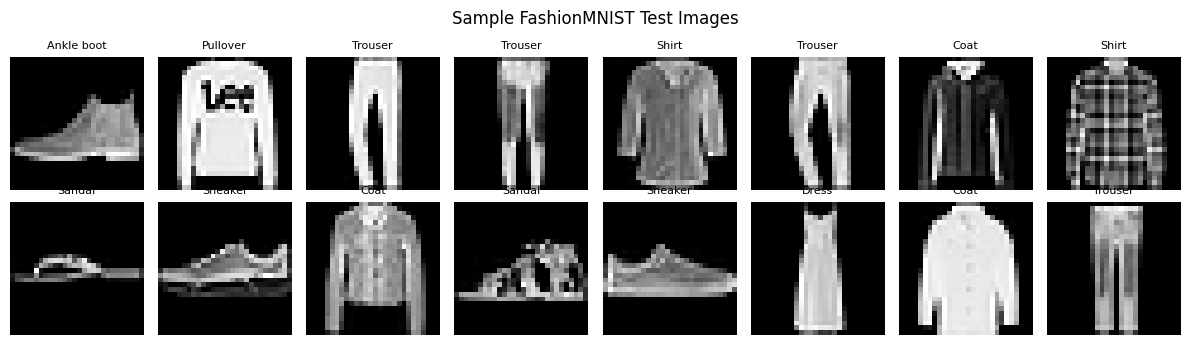

In [5]:
images, labels = next(iter(test_loader))
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, image, label in zip(axes.ravel(), images[:16], labels[:16]):
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(class_names[label.item()], fontsize=8)
    ax.axis("off")
plt.suptitle("Sample FashionMNIST Test Images")
plt.tight_layout()
plt.show()



## Part 1A: Fundamental GAN Architecture

A generative adversarial network (GAN) contains two neural networks: a
generator and a discriminator.

The **generator** receives a random latent vector `z` and transforms it into
a synthetic sample, such as an image. Its goal is to produce samples that
look like the real training data.

The **discriminator** receives either a real training example or a generated
example and predicts whether the input is real or fake. Its goal is to
correctly distinguish real data from generated data.

Training is adversarial. The discriminator is trained to maximize its ability
to classify real samples as real and generated samples as fake. The generator
is trained to fool the discriminator into classifying generated samples as
real. Therefore, the generator and discriminator improve in response to each
other.

The original minimax objective is:

`min_G max_D V(D,G) = E_x[log D(x)] + E_z[log(1 - D(G(z)))]`

where `x` is a real sample, `z` is a random latent vector, `G` is the
generator, and `D` is the discriminator. The theoretical goal is to reach a
Nash equilibrium in which generated samples follow the real data
distribution. At the ideal equilibrium, the discriminator cannot distinguish
real and generated samples better than random guessing, so its output is
approximately `0.5`.



## Part 1B: Mode Collapse

Mode collapse occurs when the generator produces only a small variety of
outputs even though the real dataset contains many different modes or
categories. For example, on FashionMNIST, a generator might repeatedly
produce images that look like the same type of shoe and fail to generate
shirts, bags, trousers, and other classes.

Mode collapse happens because the generator can discover a limited set of
outputs that successfully fool the current discriminator. Once those outputs
receive favorable feedback, gradient updates may keep moving the generator
toward those outputs instead of encouraging broad coverage of the real data
distribution. The discriminator and generator can also oscillate rather than
converge smoothly.

**Technique 1: Mini-batch discrimination.**

Mini-batch discrimination allows the discriminator to compare examples within
the same batch. If all generated samples are nearly identical, the
discriminator can detect that lack of diversity and penalize the generator.
This gives the generator an incentive to produce different samples within a
batch.

**Technique 2: Wasserstein GAN with gradient penalty (WGAN-GP).**

WGAN replaces the usual discriminator probability with a critic that provides
a smoother estimate of the distance between the real and generated
distributions. The gradient penalty encourages the critic to satisfy the
required Lipschitz constraint. More informative and stable gradients help the
generator move toward missing modes instead of receiving unstable or
vanishing feedback.

Other possible methods include feature matching, label smoothing, noise or
data augmentation for the discriminator, unrolled GANs, and diversity
regularization.



## Part 1C: Three Important GAN Variants

### 1. DCGAN

Deep Convolutional GAN replaces fully connected image networks with
convolutional architectures. The generator commonly uses transposed
convolutions to upsample a latent vector, while the discriminator uses
convolutional layers to downsample an image. Batch normalization and ReLU or
LeakyReLU activations are also commonly used. DCGAN addresses the difficulty
of modeling spatial image structure with ordinary dense layers and generally
produces sharper and more stable image samples.

### 2. Conditional GAN

A conditional GAN adds extra information, such as a class label, to both the
generator and discriminator. The generator receives a noise vector together
with the desired class, while the discriminator receives an image together
with its class condition. This allows the model to generate a requested type
of sample, such as a FashionMNIST bag or sneaker, instead of generating an
uncontrolled sample from the entire dataset.

### 3. CycleGAN

CycleGAN learns an image-to-image translation between two domains without
requiring paired examples. It uses two generators and two discriminators. A
cycle-consistency loss requires an image translated from domain A to domain B
and back to domain A to resemble the original image. This addresses the need
for paired training images in tasks such as horse-to-zebra or summer-to-winter
translation.



# Part 2: Fully Connected Autoencoder

An autoencoder has an encoder and a decoder. The encoder compresses an image
into a lower-dimensional latent representation. The decoder reconstructs the
original image from that representation. The model is trained by minimizing
reconstruction error.



In [6]:
class FCAutoencoder(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 28 * 28),
            nn.Sigmoid(),
        )

    def encode(self, x):
        x = x.view(x.size(0), -1)
        return self.encoder(x)

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        z = self.encode(x)
        reconstruction = self.decode(z)
        return reconstruction.view(-1, 1, 28, 28)


fc_ae = FCAutoencoder(latent_dim=64).to(device)
fc_optimizer = torch.optim.Adam(fc_ae.parameters(), lr=1e-3)
fc_loss_fn = nn.MSELoss()

print(fc_ae)
print("FC-AE parameters:", sum(p.numel() for p in fc_ae.parameters()))



FCAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=64, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
  )
)
FC-AE parameters: 435536


In [7]:
def train_fc_autoencoder(model, loader, optimizer, epochs=10):
    model.train()
    history = []
    start_time = time.time()

    for epoch in range(1, epochs + 1):
        running_loss = 0.0

        for x, _ in loader:
            x = x.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            reconstruction = model(x)
            loss = fc_loss_fn(reconstruction, x)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * x.size(0)

        epoch_loss = running_loss / len(loader.dataset)
        history.append(epoch_loss)
        print(f"FC-AE Epoch {epoch:02d}/{epochs} | MSE: {epoch_loss:.6f}")

    print(f"FC-AE training time: {time.time() - start_time:.1f} seconds")
    return history


FC_EPOCHS = 10
fc_history = train_fc_autoencoder(
    fc_ae, train_loader, fc_optimizer, epochs=FC_EPOCHS
)



FC-AE Epoch 01/10 | MSE: 0.031905
FC-AE Epoch 02/10 | MSE: 0.016544
FC-AE Epoch 03/10 | MSE: 0.013860
FC-AE Epoch 04/10 | MSE: 0.012306
FC-AE Epoch 05/10 | MSE: 0.011251
FC-AE Epoch 06/10 | MSE: 0.010498
FC-AE Epoch 07/10 | MSE: 0.009881
FC-AE Epoch 08/10 | MSE: 0.009414
FC-AE Epoch 09/10 | MSE: 0.009002
FC-AE Epoch 10/10 | MSE: 0.008639
FC-AE training time: 126.8 seconds


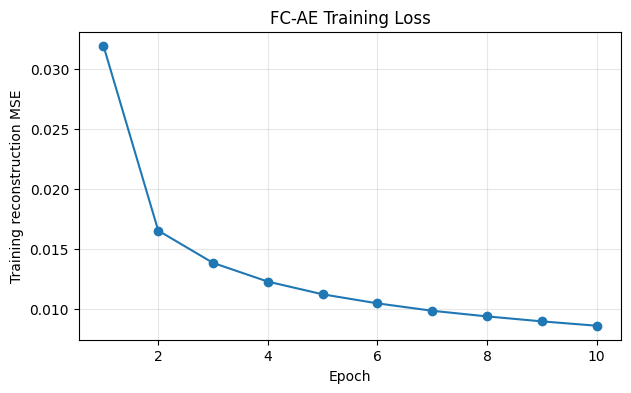

In [8]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, FC_EPOCHS + 1), fc_history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training reconstruction MSE")
plt.title("FC-AE Training Loss")
plt.grid(alpha=0.3)
plt.show()

## Part 2: Variational Autoencoder

A VAE does not encode each image as one fixed latent vector. Instead, its
encoder predicts the mean and log-variance of a latent Gaussian distribution.
A latent vector is sampled using the reparameterization trick:

`z = mean + exp(0.5 * log_variance) * epsilon`

where `epsilon` is sampled from a standard normal distribution. The VAE loss
contains two terms:

1. Reconstruction loss: encourages the decoded image to resemble the input.
2. KL-divergence loss: encourages the learned latent distribution to remain
   close to a standard normal distribution.



In [9]:
class VAE(nn.Module):
    def __init__(self, latent_dim=20):
        super().__init__()
        self.latent_dim = latent_dim

        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
        )
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 28 * 28),
            nn.Sigmoid(),
        )

    def encode(self, x):
        x = x.view(x.size(0), -1)
        hidden = self.encoder(x)
        return self.fc_mu(hidden), self.fc_logvar(hidden)

    def reparameterize(self, mu, logvar):
        standard_deviation = torch.exp(0.5 * logvar)
        epsilon = torch.randn_like(standard_deviation)
        return mu + epsilon * standard_deviation

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        reconstruction = self.decode(z)
        return reconstruction.view(-1, 1, 28, 28), mu, logvar


vae = VAE(latent_dim=20).to(device)
vae_optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)

print(vae)
print("VAE parameters:", sum(p.numel() for p in vae.parameters()))



VAE(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
  )
  (fc_mu): Linear(in_features=256, out_features=20, bias=True)
  (fc_logvar): Linear(in_features=256, out_features=20, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=20, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
  )
)
VAE parameters: 418104


In [10]:
def vae_loss_function(reconstruction, x, mu, logvar, beta=1.0):
    # Sum over pixels and then average over the batch.
    reconstruction_loss = F.binary_cross_entropy(
        reconstruction, x, reduction="sum"
    ) / x.size(0)

    # KL divergence from N(mu, sigma^2) to N(0, I).
    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    ) / x.size(0)

    total_loss = reconstruction_loss + beta * kl_loss
    return total_loss, reconstruction_loss, kl_loss


def train_vae(model, loader, optimizer, epochs=10, beta=1.0):
    model.train()
    history = {"total": [], "reconstruction": [], "kl": []}
    start_time = time.time()

    for epoch in range(1, epochs + 1):
        totals = {"total": 0.0, "reconstruction": 0.0, "kl": 0.0}

        for x, _ in loader:
            x = x.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            reconstruction, mu, logvar = model(x)
            total, reconstruction_loss, kl_loss = vae_loss_function(
                reconstruction, x, mu, logvar, beta=beta
            )
            total.backward()
            optimizer.step()

            batch_size = x.size(0)
            totals["total"] += total.item() * batch_size
            totals["reconstruction"] += reconstruction_loss.item() * batch_size
            totals["kl"] += kl_loss.item() * batch_size

        epoch_values = {
            key: value / len(loader.dataset)
            for key, value in totals.items()
        }
        for key in history:
            history[key].append(epoch_values[key])

        print(
            f"VAE Epoch {epoch:02d}/{epochs} | "
            f"Total: {epoch_values['total']:.4f} | "
            f"Recon: {epoch_values['reconstruction']:.4f} | "
            f"KL: {epoch_values['kl']:.4f}"
        )

    print(f"VAE training time: {time.time() - start_time:.1f} seconds")
    return history


VAE_EPOCHS = 10
vae_history = train_vae(
    vae, train_loader, vae_optimizer, epochs=VAE_EPOCHS, beta=1.0
)

VAE Epoch 01/10 | Total: 293.3357 | Recon: 279.1050 | KL: 14.2307
VAE Epoch 02/10 | Total: 260.0254 | Recon: 244.3833 | KL: 15.6421
VAE Epoch 03/10 | Total: 253.6337 | Recon: 238.2406 | KL: 15.3931
VAE Epoch 04/10 | Total: 250.0675 | Recon: 234.7579 | KL: 15.3096
VAE Epoch 05/10 | Total: 247.9843 | Recon: 232.6191 | KL: 15.3652
VAE Epoch 06/10 | Total: 246.6055 | Recon: 231.1109 | KL: 15.4946
VAE Epoch 07/10 | Total: 245.6424 | Recon: 230.0465 | KL: 15.5959
VAE Epoch 08/10 | Total: 244.9416 | Recon: 229.2637 | KL: 15.6779
VAE Epoch 09/10 | Total: 244.3320 | Recon: 228.6050 | KL: 15.7270
VAE Epoch 10/10 | Total: 243.8427 | Recon: 228.0750 | KL: 15.7677
VAE training time: 125.2 seconds


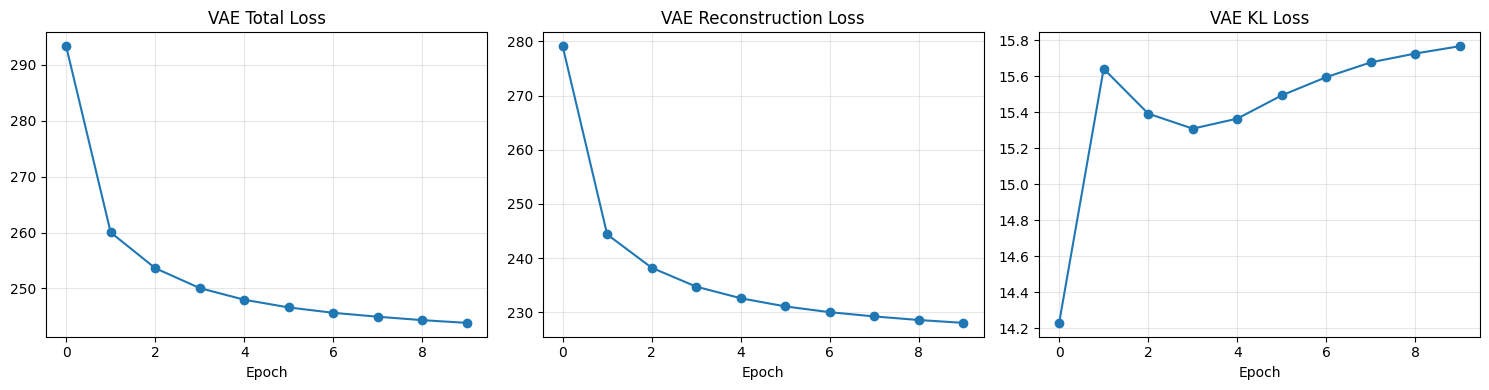

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(vae_history["total"], marker="o")
axes[0].set_title("VAE Total Loss")
axes[1].plot(vae_history["reconstruction"], marker="o")
axes[1].set_title("VAE Reconstruction Loss")
axes[2].plot(vae_history["kl"], marker="o")
axes[2].set_title("VAE KL Loss")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Evaluation Metrics

We use mean squared error (MSE) as the main reconstruction metric. Lower MSE
means that the reconstruction is numerically closer to the original image.
We also report PSNR, where higher values indicate better reconstruction
quality. The class-specific metrics use the two personal focus classes:
Pullover (`CLS_A=2`) and Bag (`CLS_B=8`).



In [12]:
@torch.no_grad()
def evaluate_fc_ae(model, loader):
    model.eval()
    total_squared_error = 0.0
    total_pixels = 0
    all_errors = []
    all_labels = []

    for x, labels in loader:
        x = x.to(device)
        reconstruction = model(x)
        squared_error = (reconstruction - x).pow(2)
        total_squared_error += squared_error.sum().item()
        total_pixels += x.numel()
        all_errors.append(squared_error.flatten(1).mean(dim=1).cpu())
        all_labels.append(labels)

    mse = total_squared_error / total_pixels
    psnr = 10 * np.log10(1.0 / max(mse, 1e-12))
    return mse, psnr, torch.cat(all_errors), torch.cat(all_labels)


@torch.no_grad()
def evaluate_vae(model, loader):
    model.eval()
    total_squared_error = 0.0
    total_pixels = 0
    all_errors = []
    all_labels = []

    for x, labels in loader:
        x = x.to(device)
        reconstruction, _, _ = model(x)
        squared_error = (reconstruction - x).pow(2)
        total_squared_error += squared_error.sum().item()
        total_pixels += x.numel()
        all_errors.append(squared_error.flatten(1).mean(dim=1).cpu())
        all_labels.append(labels)

    mse = total_squared_error / total_pixels
    psnr = 10 * np.log10(1.0 / max(mse, 1e-12))
    return mse, psnr, torch.cat(all_errors), torch.cat(all_labels)


fc_mse, fc_psnr, fc_errors, fc_labels = evaluate_fc_ae(fc_ae, test_loader)
vae_mse, vae_psnr, vae_errors, vae_labels = evaluate_vae(vae, test_loader)

def class_metrics(errors, labels, class_id):
    selected = errors[labels == class_id]
    mse = selected.mean().item()
    psnr = 10 * np.log10(1.0 / max(mse, 1e-12))
    return mse, psnr, len(selected)


fc_a = class_metrics(fc_errors, fc_labels, CLS_A)
fc_b = class_metrics(fc_errors, fc_labels, CLS_B)
vae_a = class_metrics(vae_errors, vae_labels, CLS_A)
vae_b = class_metrics(vae_errors, vae_labels, CLS_B)

results = pd.DataFrame([
    {
        "Model": "FC-AE",
        "Test MSE": fc_mse,
        "Test PSNR (dB)": fc_psnr,
        f"Class {CLS_A} MSE": fc_a[0],
        f"Class {CLS_B} MSE": fc_b[0],
    },
    {
        "Model": "VAE",
        "Test MSE": vae_mse,
        "Test PSNR (dB)": vae_psnr,
        f"Class {CLS_A} MSE": vae_a[0],
        f"Class {CLS_B} MSE": vae_b[0],
    },
])

display(results.round(6))
print(f"FC-AE class {CLS_A} ({class_names[CLS_A]}): MSE={fc_a[0]:.6f}, PSNR={fc_a[1]:.2f} dB, n={fc_a[2]}")
print(f"FC-AE class {CLS_B} ({class_names[CLS_B]}): MSE={fc_b[0]:.6f}, PSNR={fc_b[1]:.2f} dB, n={fc_b[2]}")
print(f"VAE class {CLS_A} ({class_names[CLS_A]}): MSE={vae_a[0]:.6f}, PSNR={vae_a[1]:.2f} dB, n={vae_a[2]}")
print(f"VAE class {CLS_B} ({class_names[CLS_B]}): MSE={vae_b[0]:.6f}, PSNR={vae_b[1]:.2f} dB, n={vae_b[2]}")



,Model,Test MSE,Test PSNR (dB),Class 2 MSE,Class 8 MSE
0,FC-AE,0.008607,20.651724,0.007653,0.014412
1,VAE,0.016658,17.783727,0.015869,0.024592


FC-AE class 2 (Pullover): MSE=0.007653, PSNR=21.16 dB, n=1000
FC-AE class 8 (Bag): MSE=0.014412, PSNR=18.41 dB, n=1000
VAE class 2 (Pullover): MSE=0.015869, PSNR=17.99 dB, n=1000
VAE class 8 (Bag): MSE=0.024592, PSNR=16.09 dB, n=1000


## Compare Original Images and Reconstructions



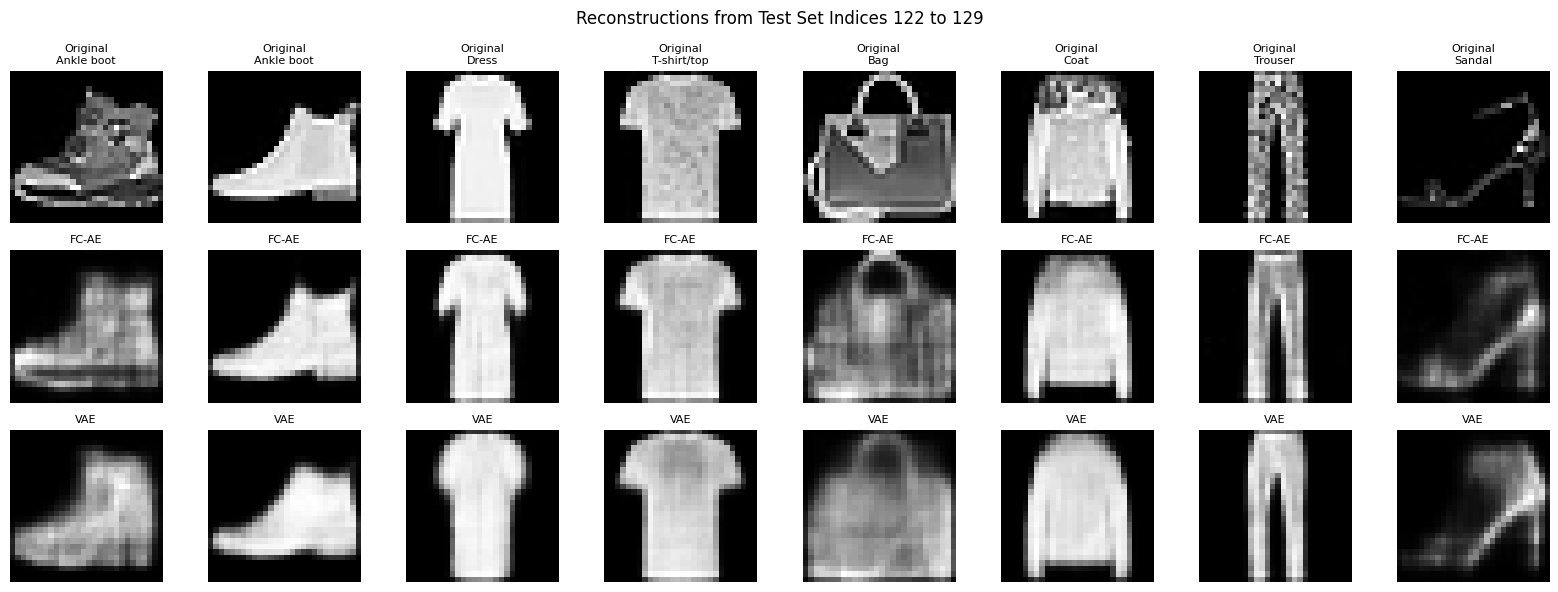

In [13]:
@torch.no_grad()
def show_reconstructions(fc_model, vae_model, dataset, start=SLICE, count=8):
    selected = [dataset[i] for i in range(start, min(start + count, len(dataset)))]
    x = torch.stack([item[0] for item in selected]).to(device)
    labels = [item[1] for item in selected]

    fc_model.eval()
    vae_model.eval()
    fc_reconstruction = fc_model(x).cpu()
    vae_reconstruction, _, _ = vae_model(x)
    vae_reconstruction = vae_reconstruction.cpu()
    x = x.cpu()

    fig, axes = plt.subplots(3, len(labels), figsize=(2 * len(labels), 6))
    for i, label in enumerate(labels):
        axes[0, i].imshow(x[i].squeeze(), cmap="gray")
        axes[0, i].set_title(f"Original\n{class_names[label]}", fontsize=8)
        axes[1, i].imshow(fc_reconstruction[i].squeeze(), cmap="gray")
        axes[1, i].set_title("FC-AE", fontsize=8)
        axes[2, i].imshow(vae_reconstruction[i].squeeze(), cmap="gray")
        axes[2, i].set_title("VAE", fontsize=8)
        for row in range(3):
            axes[row, i].axis("off")

    plt.suptitle(f"Reconstructions from Test Set Indices {start} to {start + len(labels) - 1}")
    plt.tight_layout()
    plt.show()


show_reconstructions(fc_ae, vae, test_dataset, start=SLICE, count=8)



## Generate New Images from the VAE

Because the VAE regularizes its latent space toward a standard normal
distribution, we can sample random latent vectors and decode them into new
images.



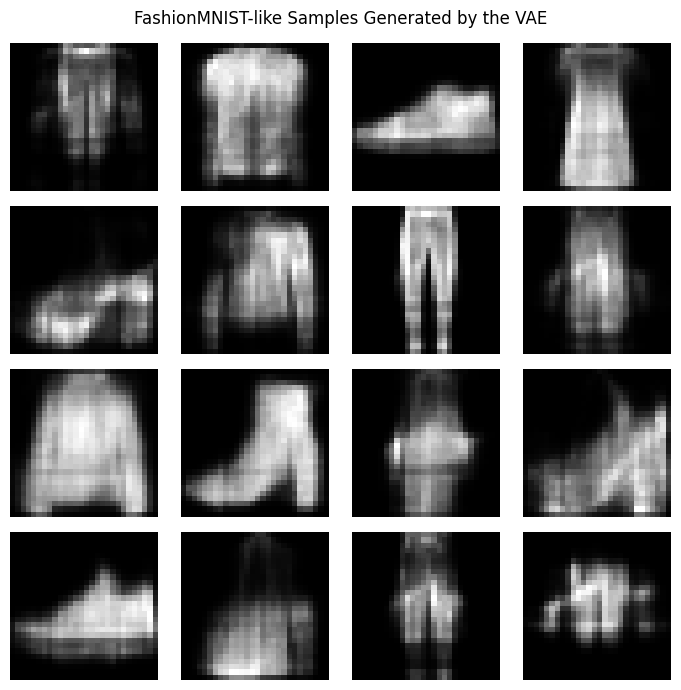

In [14]:
@torch.no_grad()
def show_vae_samples(model, number=16):
    model.eval()
    z = torch.randn(number, model.latent_dim, device=device)
    samples = model.decode(z).view(-1, 1, 28, 28).cpu()

    fig, axes = plt.subplots(4, 4, figsize=(7, 7))
    for ax, sample in zip(axes.ravel(), samples):
        ax.imshow(sample.squeeze(), cmap="gray")
        ax.axis("off")
    plt.suptitle("FashionMNIST-like Samples Generated by the VAE")
    plt.tight_layout()
    plt.show()


show_vae_samples(vae, number=16)



## VAE Latent Interpolation

Latent interpolation tests whether the VAE's latent space changes smoothly.
We encode two test images, interpolate between their latent means, and
decode the intermediate latent vectors.



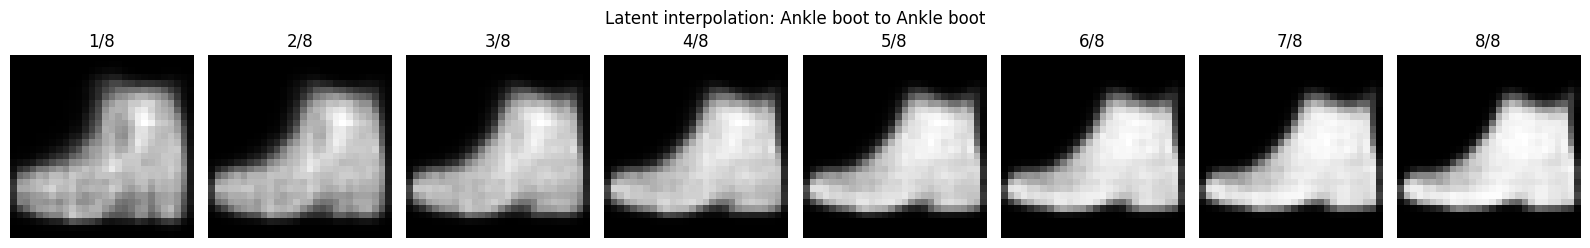

In [15]:
@torch.no_grad()
def show_latent_interpolation(model, dataset, index_a=SLICE, index_b=SLICE + 1, steps=8):
    model.eval()
    image_a, label_a = dataset[index_a]
    image_b, label_b = dataset[index_b]
    x = torch.stack([image_a, image_b]).to(device)
    mu, _ = model.encode(x)

    weights = torch.linspace(0, 1, steps, device=device).unsqueeze(1)
    z = (1 - weights) * mu[0:1] + weights * mu[1:2]
    interpolated = model.decode(z).view(-1, 1, 28, 28).cpu()

    fig, axes = plt.subplots(1, steps, figsize=(2 * steps, 2.5))
    for i, ax in enumerate(axes):
        ax.imshow(interpolated[i].squeeze(), cmap="gray")
        ax.set_title(f"{i + 1}/{steps}")
        ax.axis("off")
    plt.suptitle(
        f"Latent interpolation: {class_names[label_a]} to {class_names[label_b]}"
    )
    plt.tight_layout()
    plt.show()


show_latent_interpolation(vae, test_dataset, SLICE, SLICE + 1)



## Discussion and Final Comparison

The FC-AE directly maps each image to one deterministic latent vector. Its
reconstruction objective is simple, so it often produces lower reconstruction
error than a VAE.

The VAE represents each input as a probability distribution and adds a KL
regularization term. This usually makes its reconstructions somewhat blurrier,
but it creates a structured latent space from which new images can be sampled.
Therefore, the FC-AE is mainly useful for compression and reconstruction,
while the VAE is also a generative model.



In [16]:
best_reconstruction_model = "FC-AE" if fc_mse < vae_mse else "VAE"
best_psnr_model = "FC-AE" if fc_psnr > vae_psnr else "VAE"

display(Markdown(
    f"""
### Final Results

- The model with lower overall test reconstruction MSE was **{best_reconstruction_model}**.
- The model with higher overall test PSNR was **{best_psnr_model}**.
- The FC-AE uses a deterministic 64-dimensional representation.
- The VAE uses a 20-dimensional probabilistic representation and can generate new samples.
- The VAE's KL-divergence term regularizes its latent space, while the FC-AE only minimizes reconstruction error.
"""
))


### Final Results

- The model with lower overall test reconstruction MSE was **FC-AE**.
- The model with higher overall test PSNR was **FC-AE**.
- The FC-AE uses a deterministic 64-dimensional representation.
- The VAE uses a 20-dimensional probabilistic representation and can generate new samples.
- The VAE's KL-divergence term regularizes its latent space, while the FC-AE only minimizes reconstruction error.


## Conclusion

Both models learned useful representations of FashionMNIST images. The FC-AE
directly optimized reconstruction quality and provided a compact encoding. The
VAE added a probabilistic latent representation, which enabled random sample
generation and latent interpolation. The quantitative metrics and the image
visualizations together provide the evaluation required for this assignment.

